In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("../Student Social Media And Mental Health Impact.csv")

In [7]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [8]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 5000
Columns: 13


In [9]:
print(df.columns.tolist())

['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night', 'Stress_Level', 'Mental_Health_Score']


In [10]:
df.shape

(5000, 13)

In [11]:
# Check data types
print("DATA TYPES")
print(df.dtypes)

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Total missing values
print("\nTotal NaN:", df.isnull().sum().sum())

# Check duplicates
print("\nDuplicate records:", df.duplicated().sum())

DATA TYPES
Age                          int64
Gender                      object
Country                     object
Academic_Level              object
Most_Used_Platform          object
Purpose_Of_Use              object
Avg_Daily_Usage_Hours      float64
Daily_Unlocks                int64
Study_Hours                float64
Physical_Activity_Hours    float64
Sleep_Hours_Per_Night      float64
Stress_Level                object
Mental_Health_Score        float64
dtype: object

MISSING VALUES
Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

Total NaN: 0

Duplicate records: 2


In [12]:
# Remove duplicate records
df = df.drop_duplicates()

df.shape


(4998, 13)

In [13]:
X = df.drop(columns=["Mental_Health_Score", "Stress_Level"])
y = df["Mental_Health_Score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (4998, 11)
Target shape: (4998,)


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3998, 11)
Testing data: (1000, 11)


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Define feature groups
numerical_features = [
    "Age",
    "Avg_Daily_Usage_Hours",
    "Daily_Unlocks",
    "Study_Hours",
    "Physical_Activity_Hours",
    "Sleep_Hours_Per_Night"
]

nominal_features = [
    "Gender",
    "Country",
    "Most_Used_Platform",
    "Purpose_Of_Use"
]

ordinal_features = ["Academic_Level"]

# Define academic order
academic_order = [
    ["High School", "Undergraduate", "Graduate", "Postgraduate"]
]

# Create preprocessor
preprocessor = ColumnTransformer([
    ("num", "passthrough", numerical_features),

    ("nominal", OneHotEncoder(handle_unknown="ignore"),
     nominal_features),

    ("ordinal", OrdinalEncoder(
        categories=academic_order,
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ), ordinal_features)
])

print("Encoding configured successfully!")

Encoding configured successfully!


In [16]:
X_encoded = preprocessor.fit_transform(X_train)

if hasattr(X_encoded, "toarray"):
    X_encoded = X_encoded.toarray()

X_encoded_df = pd.DataFrame(
    X_encoded,
    columns=preprocessor.get_feature_names_out(),
    index=X_train.index
)

display(X_encoded_df.head())

,num__Age,num__Avg_Daily_Usage_Hours,num__Daily_Unlocks,num__Study_Hours,num__Physical_Activity_Hours,num__Sleep_Hours_Per_Night,nominal__Gender_Female,nominal__Gender_Male,nominal__Country_Afghanistan,nominal__Country_Albania,...,nominal__Most_Used_Platform_Twitter,nominal__Most_Used_Platform_VKontakte,nominal__Most_Used_Platform_WeChat,nominal__Most_Used_Platform_WhatsApp,nominal__Most_Used_Platform_YouTube,nominal__Purpose_Of_Use_Education,nominal__Purpose_Of_Use_Entertainment,nominal__Purpose_Of_Use_Networking,nominal__Purpose_Of_Use_News,ordinal__Academic_Level
1738,19.0,5.1,181.0,3.3,1.4,7.1,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3988,18.0,1.6,98.0,5.9,3.6,7.7,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2917,20.0,4.0,169.0,2.5,1.7,7.4,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1595,21.0,5.8,204.0,2.8,1.1,6.7,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3215,23.0,7.4,232.0,0.5,0.0,5.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0


In [23]:
# Transform test data using the already-fitted preprocessor
X_test_encoded = preprocessor.transform(X_test)

# Convert sparse matrix if necessary
if hasattr(X_test_encoded, "toarray"):
    X_test_encoded = X_test_encoded.toarray()

print("Test data encoded successfully!")
print("Encoded test shape:", X_test_encoded.shape)

Test data encoded successfully!
Encoded test shape: (1000, 128)


In [24]:
from sklearn.linear_model import LinearRegression

# Create model
lr_model = LinearRegression()

# Train model using encoded training data
lr_model.fit(X_encoded, y_train)

print("Linear Regression training completed!")

Linear Regression training completed!


In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict using test data
lr_pred = lr_model.predict(X_test_encoded)

# Calculate metrics
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_r2 = r2_score(y_test, lr_pred)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("MAE:", round(lr_mae, 3))
print("RMSE:", round(lr_rmse, 3))
print("R2 Score:", round(lr_r2, 3))

LINEAR REGRESSION RESULTS
-------------------------
MAE: 0.48
RMSE: 0.622
R2 Score: 0.784


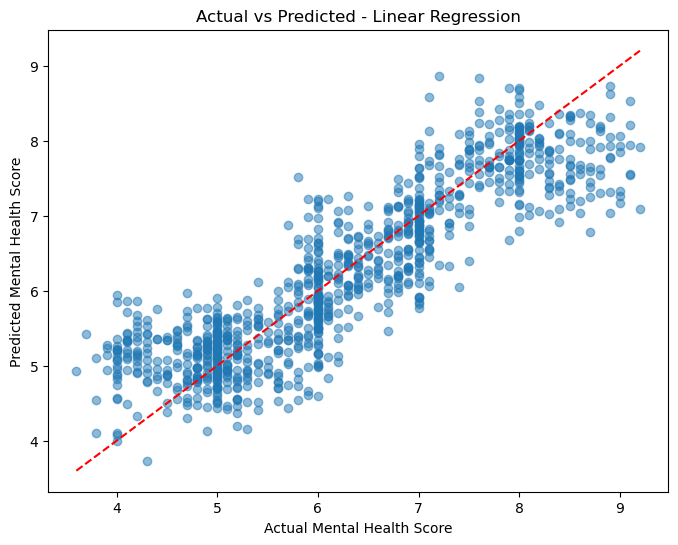

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Use lr_pred instead of y_pred
plt.scatter(y_test, lr_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Mental Health Score")
plt.ylabel("Predicted Mental Health Score")
plt.title("Actual vs Predicted - Linear Regression")

plt.show()

In [27]:
from sklearn.ensemble import RandomForestRegressor

# Create model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train using encoded data
rf_model.fit(X_encoded, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Transform test data using the fitted encoder
X_test_encoded = preprocessor.transform(X_test)

if hasattr(X_test_encoded, "toarray"):
    X_test_encoded = X_test_encoded.toarray()

# Make predictions
y_pred = rf_model.predict(X_test_encoded)

# Calculate metrics
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("R2 Score:", round(r2_score(y_test, y_pred), 3))

MAE: 0.277
RMSE: 0.387
R2 Score: 0.916


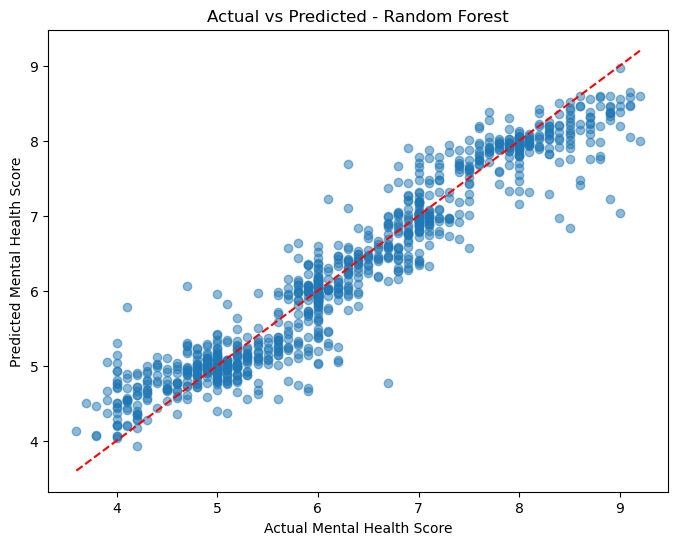

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Mental Health Score")
plt.ylabel("Predicted Mental Health Score")
plt.title("Actual vs Predicted - Random Forest")

plt.show()

In [30]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Linear Regression"],
    "MAE": [0.277, lr_mae],
    "RMSE": [0.387, lr_rmse],
    "R2 Score": [0.916, lr_r2]
})

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.277000,0.387000,0.916000
1,Linear Regression,0.479654,0.621664,0.783517


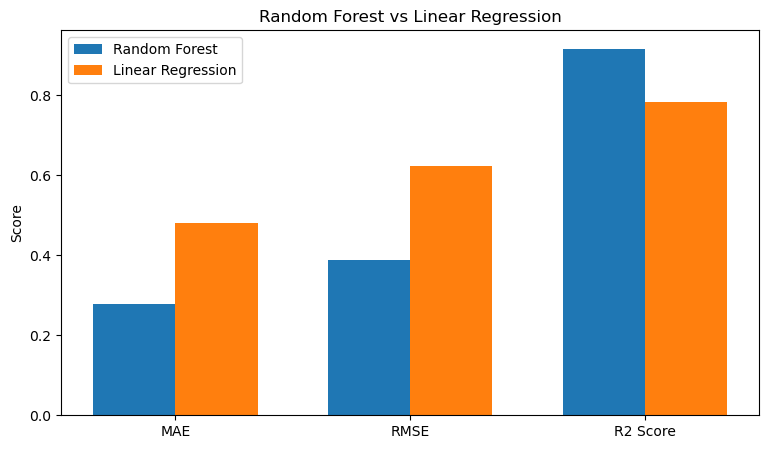

In [31]:
import matplotlib.pyplot as plt

metrics = ["MAE", "RMSE", "R2 Score"]

rf_scores = [0.277, 0.387, 0.916]
lr_scores = [0.479654, 0.621664, 0.783517]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, rf_scores, width, label="Random Forest")
plt.bar(x + width/2, lr_scores, width, label="Linear Regression")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Random Forest vs Linear Regression")
plt.legend()
plt.show()

In [32]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create model
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train
gb_model.fit(X_encoded, y_train)

# Predict
gb_pred = gb_model.predict(X_test_encoded)

# Evaluate
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting Results")
print("-------------------------")
print("MAE:", round(gb_mae, 4))
print("RMSE:", round(gb_rmse, 4))
print("R2 Score:", round(gb_r2, 4))

Gradient Boosting Results
-------------------------
MAE: 0.4121
RMSE: 0.5317
R2 Score: 0.8416


In [33]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Linear Regression",
        "Gradient Boosting"
    ],
    "MAE": [0.277, lr_mae, gb_mae],
    "RMSE": [0.387, lr_rmse, gb_rmse],
    "R2 Score": [0.916, lr_r2, gb_r2]
})

display(comparison.sort_values("R2 Score", ascending=False))

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.277000,0.387000,0.916000
2,Gradient Boosting,0.412063,0.531727,0.841624
1,Linear Regression,0.479654,0.621664,0.783517


In [34]:
best_model_name = comparison.loc[
    comparison["R2 Score"].idxmax(), "Model"
]

print("Selected Model:", best_model_name)

Selected Model: Random Forest


In [36]:
import os
import joblib
from sklearn.pipeline import Pipeline

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Combine fitted preprocessing and trained Random Forest
mindwell_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", rf_model)
])

# Save model in models folder
joblib.dump(
    mindwell_pipeline,
    "../models/MindWell_AI_Model.pkl"
)

print("MindWell AI model saved successfully!")

MindWell AI model saved successfully!


In [37]:
import os

model_path = "../models/MindWell_AI_Model.pkl"

print("Model exists:", os.path.exists(model_path))
print("Model size:", round(os.path.getsize(model_path) / 1024, 2), "KB")

Model exists: True
Model size: 55728.63 KB
